# M1 — Corrected Siamese U-Net baseline for LEVIR-CD

This notebook establishes the baseline used for the later architecture experiments. It uses a shared ImageNet-pretrained ResNet50 encoder to extract features from the before and after images. The absolute difference between corresponding feature maps is passed to a U-Net-style decoder, which produces a one-channel change mask.

The data pipeline includes filename-based pairing, RGB conversion, ResNet50 preprocessing and nearest-neighbour mask resizing. The model is trained in two stages: first with a frozen encoder, then by fine-tuning the final encoder stage.

**Dataset split:** 445 training, 64 validation and 128 test image pairs. **Input size:** 128 × 128.

## 1. Connect Google Drive and set the dataset location

Mount Google Drive, then set `DATASET_ROOT` to the directory containing the `train`, `val` and `test` folders.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# EDIT THIS to the directory containing train/, val/, and test/
DATASET_ROOT = "/content/drive/MyDrive/LEVIR-CD/LEVIR CD"

# Expected subfolder names
SPLITS = {
    "train": "train",
    "val": "val",
    "test": "test",
}

IMG_SIZE = 128
BATCH_SIZE = 4
SEED = 42

import os
os.makedirs("/content/m1_checkpoints", exist_ok=True)

for split_name, folder in SPLITS.items():
    split_path = os.path.join(DATASET_ROOT, folder)
    assert os.path.isdir(split_path), f"Missing split folder: {split_path}"

print("Dataset root:", DATASET_ROOT)
print("GPU devices:", __import__("tensorflow").config.list_physical_devices("GPU"))

Mounted at /content/drive
Dataset root: /content/drive/MyDrive/LEVIR-CD/LEVIR CD
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Imports and reproducibility

This section imports the libraries used for image loading, model construction, training and evaluation. The random seeds and runtime settings are defined here so the experiment can be repeated with the same configuration.

In [2]:
import os
import random
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Avoid TensorFlow reserving all GPU memory at startup.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Match the before, after and label files

Image pairs are matched by filename stem across the `A`, `B` and `label` folders. The checks stop execution if a sample is missing from any folder, preventing unrelated files from being paired by list position.

In [3]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def index_images(folder):
    folder = Path(folder)
    files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]
    indexed = {}
    for path in files:
        key = path.stem
        if key in indexed:
            raise ValueError(f"Duplicate filename stem '{key}' in {folder}")
        indexed[key] = str(path)
    return indexed

def build_pairs(split_name):
    split_dir = os.path.join(DATASET_ROOT, SPLITS[split_name])
    a_map = index_images(os.path.join(split_dir, "A"))
    b_map = index_images(os.path.join(split_dir, "B"))
    y_map = index_images(os.path.join(split_dir, "label"))

    ids_a, ids_b, ids_y = set(a_map), set(b_map), set(y_map)
    if not (ids_a == ids_b == ids_y):
        raise ValueError(
            f"Filename mismatch in {split_name}: "
            f"A-only={sorted(ids_a-ids_b)[:5]}, "
            f"B-only={sorted(ids_b-ids_a)[:5]}, "
            f"label-missing={sorted(ids_a-ids_y)[:5]}, "
            f"label-only={sorted(ids_y-ids_a)[:5]}"
        )

    sample_ids = sorted(ids_a)
    pairs = [(a_map[k], b_map[k], y_map[k], k) for k in sample_ids]
    print(f"{split_name}: {len(pairs)} verified pairs")
    return pairs

train_pairs = build_pairs("train")
val_pairs = build_pairs("val")
test_pairs = build_pairs("test")

expected_counts = {"train": 445, "val": 64, "test": 128}
actual_counts = {
    "train": len(train_pairs),
    "val": len(val_pairs),
    "test": len(test_pairs),
}
print("Actual counts:", actual_counts)
for split, expected in expected_counts.items():
    if actual_counts[split] != expected:
        print(f"WARNING: {split} has {actual_counts[split]} pairs; "
              f"Kaggle description says {expected}. Check folder contents.")

train: 445 verified pairs
val: 64 verified pairs
test: 128 verified pairs
Actual counts: {'train': 445, 'val': 64, 'test': 128}


## 4. Load and preprocess the image pairs

The before and after images are converted to RGB and resized using area interpolation. Label masks use nearest-neighbour interpolation to preserve their binary values. ResNet50 preprocessing is applied in the input pipeline using the expected 0–255 pixel scale.

In [5]:
def read_rgb_image(path):
    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image, (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )
    return image.astype(np.uint8)

def read_binary_mask(path):
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {path}")
    mask = cv2.resize(
        mask, (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_NEAREST
    )
    # LEVIR-CD masks are binary (typically 0 and 255).
    # Any non-zero label is treated as changed.
    mask = (mask > 0).astype(np.float32)
    return mask[..., np.newaxis]

def load_split(pairs, split_name):
    images_a, images_b, masks = [], [], []
    for path_a, path_b, path_mask, sample_id in pairs:
        images_a.append(read_rgb_image(path_a))
        images_b.append(read_rgb_image(path_b))
        masks.append(read_binary_mask(path_mask))

    X_a = np.stack(images_a).astype(np.uint8)
    X_b = np.stack(images_b).astype(np.uint8)
    Y = np.stack(masks).astype(np.float32)

    print(
        f"{split_name}: A={X_a.shape}, B={X_b.shape}, "
        f"mask={Y.shape}, mask values={np.unique(Y)}"
    )
    return X_a, X_b, Y

X1_train, X2_train, y_train = load_split(train_pairs, "train")
X1_val, X2_val, y_val = load_split(val_pairs, "validation")

# Test files are deliberately not loaded/evaluated until final testing.
print("Test pairs reserved:", len(test_pairs))

train: A=(445, 128, 128, 3), B=(445, 128, 128, 3), mask=(445, 128, 128, 1), mask values=[0. 1.]
validation: A=(64, 128, 128, 3), B=(64, 128, 128, 3), mask=(64, 128, 128, 1), mask values=[0. 1.]
Test pairs reserved: 128


## 5. Check sample alignment

The plots below show examples from the two dates and their reference change masks. Check that all three images refer to the same scene and that the mask marks the expected changed regions.

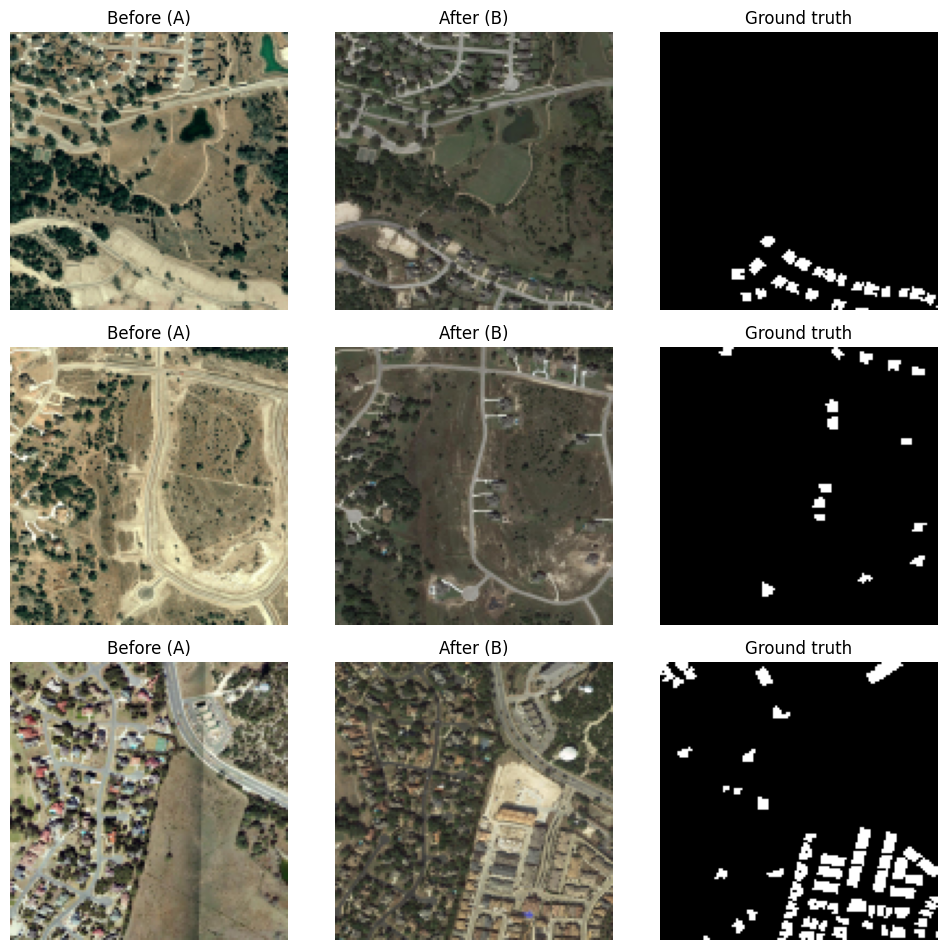

In [6]:
def show_samples(Xa, Xb, Y, n=3):
    n = min(n, len(Xa))
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.2*n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)
    for i in range(n):
        axes[i, 0].imshow(Xa[i])
        axes[i, 0].set_title("Before (A)")
        axes[i, 1].imshow(Xb[i])
        axes[i, 1].set_title("After (B)")
        axes[i, 2].imshow(Y[i, ..., 0], cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Ground truth")
        for ax in axes[i]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(X1_train, X2_train, y_train, n=3)

## 6. Prepare the TensorFlow datasets

The training pipeline applies the same spatial transformations to both dates and the label mask. Brightness changes, where enabled, are shared by the two dates. Validation and test samples are not augmented.

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_resnet_pair(image_a, image_b):
    # Inputs are RGB float tensors in the original 0..255 scale.
    image_a = tf.keras.applications.resnet50.preprocess_input(
        tf.cast(image_a, tf.float32)
    )
    image_b = tf.keras.applications.resnet50.preprocess_input(
        tf.cast(image_b, tf.float32)
    )
    return (image_a, image_b)

def augment_pair_tf(image_a, image_b, mask):
    # Cast images to float32 to perform brightness modifications safely
    image_a = tf.cast(image_a, tf.float32)
    image_b = tf.cast(image_b, tf.float32)
    mask = tf.cast(mask, tf.float32)

    # Synchronized horizontal and vertical flips.
    do_flip_lr = tf.random.uniform(()) > 0.5
    image_a = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(image_a), lambda: image_a)
    image_b = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(image_b), lambda: image_b)
    mask = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(mask), lambda: mask)

    do_flip_ud = tf.random.uniform(()) > 0.5
    image_a = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(image_a), lambda: image_a)
    image_b = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(image_b), lambda: image_b)
    mask = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(mask), lambda: mask)

    # Synchronized rotation by 0, 90, 180 or 270 degrees.
    k = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    image_a = tf.image.rot90(image_a, k)
    image_b = tf.image.rot90(image_b, k)
    mask = tf.image.rot90(mask, k)

    # Same brightness multiplier for both dates.
    brightness_factor = tf.random.uniform((), 0.8, 1.2)
    image_a = tf.clip_by_value(image_a * brightness_factor, 0.0, 255.0)
    image_b = tf.clip_by_value(image_b * brightness_factor, 0.0, 255.0)

    return image_a, image_b, mask

def make_dataset(Xa, Xb, Y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((Xa, Xb, Y))
    if training:
        ds = ds.shuffle(
            buffer_size=len(Xa),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        ds = ds.map(augment_pair_tf, num_parallel_calls=AUTOTUNE)

    ds = ds.map(
        lambda a, b, y: (preprocess_resnet_pair(a, b), y),
        num_parallel_calls=AUTOTUNE
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    if not training:
        ds = ds.cache()
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(X1_train, X2_train, y_train, training=True)
val_ds = make_dataset(X1_val, X2_val, y_val, training=False)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Training batches: 112
Validation batches: 16


## 7. Build the Siamese U-Net baseline

The shared ResNet50 encoder extracts features from both dates. The absolute difference between corresponding feature maps is passed to the U-Net decoder, which predicts the binary change mask.

In [9]:
@tf.keras.utils.register_keras_serializable()
class AbsoluteDifference(layers.Layer):
    def call(self, inputs):
        return tf.abs(inputs[0] - inputs[1])

def build_siamese_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    input_a = layers.Input(shape=input_shape, name="image_before")
    input_b = layers.Input(shape=input_shape, name="image_after")

    resnet = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )

    feature_layer_names = [
        "conv1_relu",          # 64 x 64
        "conv2_block3_out",    # 32 x 32
        "conv3_block4_out",    # 16 x 16
        "conv4_block6_out"     # 8 x 8
    ]

    encoder = tf.keras.Model(
        inputs=resnet.input,
        outputs=[resnet.get_layer(name).output for name in feature_layer_names],
        name="shared_resnet50_encoder"
    )
    encoder.trainable = False

    features_a = encoder(input_a)
    features_b = encoder(input_b)

    differences = [
        AbsoluteDifference(name=f"absolute_difference_{i}")([fa, fb])
        for i, (fa, fb) in enumerate(zip(features_a, features_b))
    ]

    # Decoder: 8 -> 16 -> 32 -> 64 -> 128
    x = differences[-1]

    x = layers.UpSampling2D(interpolation="nearest")(x)
    x = layers.Concatenate()([x, differences[2]])
    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)

    x = layers.UpSampling2D(interpolation="nearest")(x)
    x = layers.Concatenate()([x, differences[1]])
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)

    x = layers.UpSampling2D(interpolation="nearest")(x)
    x = layers.Concatenate()([x, differences[0]])
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)

    x = layers.UpSampling2D(interpolation="nearest")(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)

    output = layers.Conv2D(
        1, 1, activation="sigmoid", dtype="float32", name="change_probability"
    )(x)

    model = models.Model([input_a, input_b], output, name="M1_Siamese_UNet")
    return model, encoder

model, encoder = build_siamese_unet()
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "M1_Siamese_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_before        │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_after         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_resnet50_en… │ [(None, 64, 64,   │  8,589,184 │ image_before[0][… │
│ (Functional)        │ 64), (None, 32,   │            │ image_after[0][0] │
│                     │ 32, 256), (None,  │            │                   │
│                     │ 16, 16, 512),     │            │                   │
│                     │ (None, 8, 8,      │            │                   │
│                     │ 1024)]            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ absolute_differenc… │ (None, 8, 8,      │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 1024)             │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 16, 16,    │          0 │ absolute_differe… │
│ (UpSampling2D)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ absolute_differenc… │ (None, 16, 16,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 512)              │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 1536)             │            │ absolute_differe… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 16, 16,    │  3,539,200 │ concatenate[0][0] │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 32, 32,    │          0 │ conv2d[0][0]      │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ absolute_differenc… │ (None, 32, 32,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 256)              │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 32, 32,    │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 512)              │            │ absolute_differe… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │    589,952 │ concatenate_1[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_2     │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ absolute_differenc… │ (None, 64, 64,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 64)               │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 64, 64,    │          0 │ up_sampling2d_2[… │
│ (Concatenate)       │ 192)              │            │ absolute_differe… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 12,847,489 (49.01 MB)

 Trainable params: 4,258,305 (16.24 MB)

 Non-trainable params: 8,589,184 (32.77 MB)

## 8. Loss function and metrics

This section defines the training loss and the metrics used to monitor segmentation performance. The reported test metrics are calculated separately using the validation-selected probability threshold.

In [10]:
def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    axes = [1, 2, 3]
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    denominator = (
        tf.reduce_sum(y_true, axis=axes) +
        tf.reduce_sum(y_pred, axis=axes)
    )
    dice = (2.0 * intersection + smooth) / (denominator + smooth)
    return 1.0 - tf.reduce_mean(dice)

def combined_loss(y_true, y_pred):
    bce = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(y_true, y_pred)
    )
    return bce + dice_loss(y_true, y_pred)

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=combined_loss,
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="binary_accuracy", threshold=0.5),
            tf.keras.metrics.Precision(name="precision", thresholds=0.5),
            tf.keras.metrics.Recall(name="recall", thresholds=0.5),
            tf.keras.metrics.BinaryIoU(
                target_class_ids=[1], threshold=0.5, name="change_iou"
            )
        ]
    )

compile_model(model, learning_rate=1e-4)

## 9. Stage 1 — train the decoder

The encoder is frozen during the first stage, while the decoder and fusion layers are trained. The best checkpoint is selected using validation loss.

In [11]:
STAGE1_EPOCHS = 8
stage1_weights = "/content/m1_checkpoints/m1_stage1_best.weights.h5"

stage1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        stage1_weights,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    )
]

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE1_EPOCHS,
    callbacks=stage1_callbacks,
    verbose=1
)

model.load_weights(stage1_weights)
print("Restored best Stage 1 weights.")

Epoch 1/8
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - binary_accuracy: 0.9470 - change_iou: 0.0390 - loss: 1.1660 - precision: 0.1504 - recall: 0.0495
Epoch 1: val_loss improved from None to 0.98566, saving model to /content/m1_checkpoints/m1_stage1_best.weights.h5

Epoch 1: finished saving model to /content/m1_checkpoints/m1_stage1_best.weights.h5
112/112 ━━━━━━━━━━━━━━━━━━━━ 50s 196ms/step - binary_accuracy: 0.9450 - change_iou: 0.1056 - loss: 1.0925 - precision: 0.2940 - recall: 0.1415 - val_binary_accuracy: 0.9545 - val_change_iou: 0.1466 - val_loss: 0.9857 - val_precision: 0.4094 - val_recall: 0.1860 - learning_rate: 1.0000e-04
Epoch 2/8
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - binary_accuracy: 0.9303 - change_iou: 0.2124 - loss: 0.9884 - precision: 0.3333 - recall: 0.3698
Epoch 2: val_loss improved from 0.98566 to 0.92762, saving model to /content/m1_checkpoints/m1_stage1_best.weights.h5

Epoch 2: finished saving model to /content/m1_checkpoints/m1_stage1_best.weights.h5
112/

## 10. Stage 2 — fine-tune the encoder

The selected convolutional layers in the final ResNet50 stage are unfrozen for fine-tuning. Batch Normalization layers remain frozen, and a lower learning rate is used for this stage.

In [12]:
# Unfreeze only convolutional layers in the ResNet conv4 stage.
encoder.trainable = True
for layer in encoder.layers:
    if layer.name.startswith("conv4_") and not isinstance(
        layer, tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True
    else:
        layer.trainable = False

trainable_encoder_layers = [
    layer.name for layer in encoder.layers if layer.trainable
]
print("Trainable encoder layers:", len(trainable_encoder_layers))
print(trainable_encoder_layers[:10])

# Recompile after changing trainable flags.
compile_model(model, learning_rate=1e-5)

STAGE2_EPOCHS = 40
stage2_weights = "/content/m1_checkpoints/m1_stage2_best.weights.h5"

stage2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        stage2_weights,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE2_EPOCHS,
    callbacks=stage2_callbacks,
    verbose=1
)

model.load_weights(stage2_weights)
print("Restored best Stage 2 weights.")

Trainable encoder layers: 43
['conv4_block1_1_conv', 'conv4_block1_1_relu', 'conv4_block1_2_conv', 'conv4_block1_2_relu', 'conv4_block1_0_conv', 'conv4_block1_3_conv', 'conv4_block1_add', 'conv4_block1_out', 'conv4_block2_1_conv', 'conv4_block2_1_relu']
Epoch 1/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - binary_accuracy: 0.9547 - change_iou: 0.3443 - loss: 0.7830 - precision: 0.4721 - recall: 0.5604
Epoch 1: val_loss improved from None to 0.83098, saving model to /content/m1_checkpoints/m1_stage2_best.weights.h5

Epoch 1: finished saving model to /content/m1_checkpoints/m1_stage2_best.weights.h5
112/112 ━━━━━━━━━━━━━━━━━━━━ 49s 215ms/step - binary_accuracy: 0.9517 - change_iou: 0.3439 - loss: 0.7902 - precision: 0.4779 - recall: 0.5510 - val_binary_accuracy: 0.9541 - val_change_iou: 0.3331 - val_loss: 0.8310 - val_precision: 0.4609 - val_recall: 0.5457 - learning_rate: 1.0000e-05
Epoch 2/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - binary_accuracy: 0.9485 - change_iou: 0.3459 - l

## 11. Select the checkpoint using validation data

Stage 1 and Stage 2 checkpoints are compared on the validation set. The checkpoint with the lower validation loss is retained for threshold selection and final evaluation.

In [13]:
# Evaluate Stage 2 checkpoint.
model.load_weights(stage2_weights)
stage2_val_loss = float(model.evaluate(val_ds, verbose=0)[0])

# Evaluate Stage 1 checkpoint.
model.load_weights(stage1_weights)
stage1_val_loss = float(model.evaluate(val_ds, verbose=0)[0])

if stage2_val_loss <= stage1_val_loss:
    model.load_weights(stage2_weights)
    selected_stage = "Stage 2 (fine-tuned encoder)"
    selected_val_loss = stage2_val_loss
else:
    model.load_weights(stage1_weights)
    selected_stage = "Stage 1 (frozen encoder)"
    selected_val_loss = stage1_val_loss

print("Stage 1 validation loss:", stage1_val_loss)
print("Stage 2 validation loss:", stage2_val_loss)
print("Selected checkpoint:", selected_stage)
print("Selected validation loss:", selected_val_loss)

FINAL_MODEL_PATH = "/content/m1_checkpoints/M1_Siamese_UNet.keras"
model.save(FINAL_MODEL_PATH)
print("Saved model:", FINAL_MODEL_PATH)

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 98 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Stage 1 validation loss: 0.8431820273399353
Stage 2 validation loss: 0.8101950883865356
Selected checkpoint: Stage 2 (fine-tuned encoder)
Selected validation loss: 0.8101950883865356
Saved model: /content/m1_checkpoints/M1_Siamese_UNet.keras


## 12. Training history

The plots show the training and validation curves for each stage. They provide a view of convergence and any gap between training and validation performance.

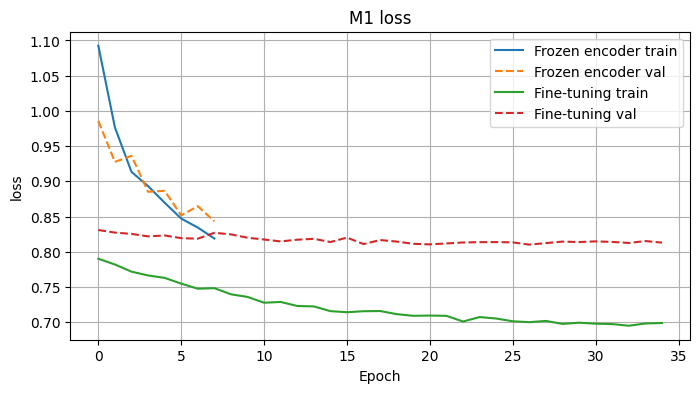

In [14]:
def plot_histories(*histories, labels=None, metric="loss"):
    plt.figure(figsize=(8, 4))
    for i, hist in enumerate(histories):
        label = labels[i] if labels else f"Stage {i+1}"
        if metric in hist.history:
            plt.plot(hist.history[metric], label=f"{label} train")
        val_key = "val_" + metric
        if val_key in hist.history:
            plt.plot(hist.history[val_key], linestyle="--", label=f"{label} val")
    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"M1 {metric}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_histories(history_stage1, history_stage2,
               labels=["Frozen encoder", "Fine-tuning"], metric="loss")

## 13. Choose the probability threshold on validation data

The threshold is selected from validation predictions using the predefined threshold grid and F1 score. The selected value is then fixed before the test set is evaluated.

In [15]:
def predict_dataset(model, dataset):
    return model.predict(dataset, verbose=1)

val_probs = predict_dataset(model, val_ds)

def binary_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(np.uint8).reshape(-1)
    y_pred = (np.asarray(y_prob).reshape(-1) >= threshold).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    iou = tp / max(tp + fp + fn, 1)
    dice = 2 * tp / max(2 * tp + fp + fn, 1)

    return {
        "threshold": float(threshold),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "dice": dice,
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)
    }

thresholds = np.arange(0.05, 0.96, 0.05)
val_rows = [
    binary_metrics(y_val, val_probs, threshold=t)
    for t in thresholds
]
val_threshold_table = pd.DataFrame(val_rows)
display(val_threshold_table)

best_idx = val_threshold_table["f1"].idxmax()
BEST_THRESHOLD = float(val_threshold_table.loc[best_idx, "threshold"])
print("Selected validation threshold:", BEST_THRESHOLD)
print("Validation metrics at selected threshold:")
display(pd.DataFrame([val_rows[best_idx]]))

16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.05,0.915303,0.310492,0.830669,0.452024,0.292010,0.452024,36630,81344,7467,923135
1,0.10,0.928921,0.347243,0.784452,0.481394,0.316997,0.481394,34592,65027,9505,939452
2,0.15,0.936602,0.373649,0.750459,0.498899,0.332356,0.498899,33093,55474,11004,949005
3,0.20,0.941789,0.394765,0.720616,0.510093,0.342366,0.510093,31777,48719,12320,955760
4,0.25,0.945665,0.413034,0.693449,0.517709,0.349263,0.517709,30579,43456,13518,961023
5,0.30,0.948674,0.429090,0.667052,0.522242,0.353401,0.522242,29415,39137,14682,965342
6,0.35,0.951197,0.444505,0.642742,0.525552,0.356440,0.525552,28343,35420,15754,969059
7,0.40,0.953333,0.459229,0.617752,0.526824,0.357611,0.526824,27241,32078,16856,972401
8,0.45,0.955130,0.473263,0.592671,0.526279,0.357109,0.526279,26135,29088,17962,975391
9,0.50,0.956638,0.486607,0.564800,0.522796,0.353909,0.522796,24906,26277,19191,978202


Selected validation threshold: 0.4
Validation metrics at selected threshold:


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.4,0.953333,0.459229,0.617752,0.526824,0.357611,0.526824,27241,32078,16856,972401


## 14. Evaluate on the held-out test set

The selected checkpoint and fixed threshold are applied to the test split. These results are the final evaluation for this run; the test labels are not used to adjust model settings.

In [16]:
X1_test, X2_test, y_test = load_split(test_pairs, "test")
test_ds = make_dataset(X1_test, X2_test, y_test, training=False)

test_probs = predict_dataset(model, test_ds)
test_results = binary_metrics(y_test, test_probs, threshold=BEST_THRESHOLD)

print("M1 FINAL TEST RESULTS")
display(pd.DataFrame([test_results]))

test: A=(128, 128, 128, 3), B=(128, 128, 128, 3), mask=(128, 128, 128, 1), mask values=[0. 1.]
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step
M1 FINAL TEST RESULTS


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.4,0.945137,0.469347,0.597075,0.525562,0.356449,0.525562,63727,72051,43005,1918369


## 15. Inspect predicted change masks

The visualizations compare the input images, reference mask and model prediction. They are included to complement the numerical metrics and show examples of missed and incorrectly detected changes.

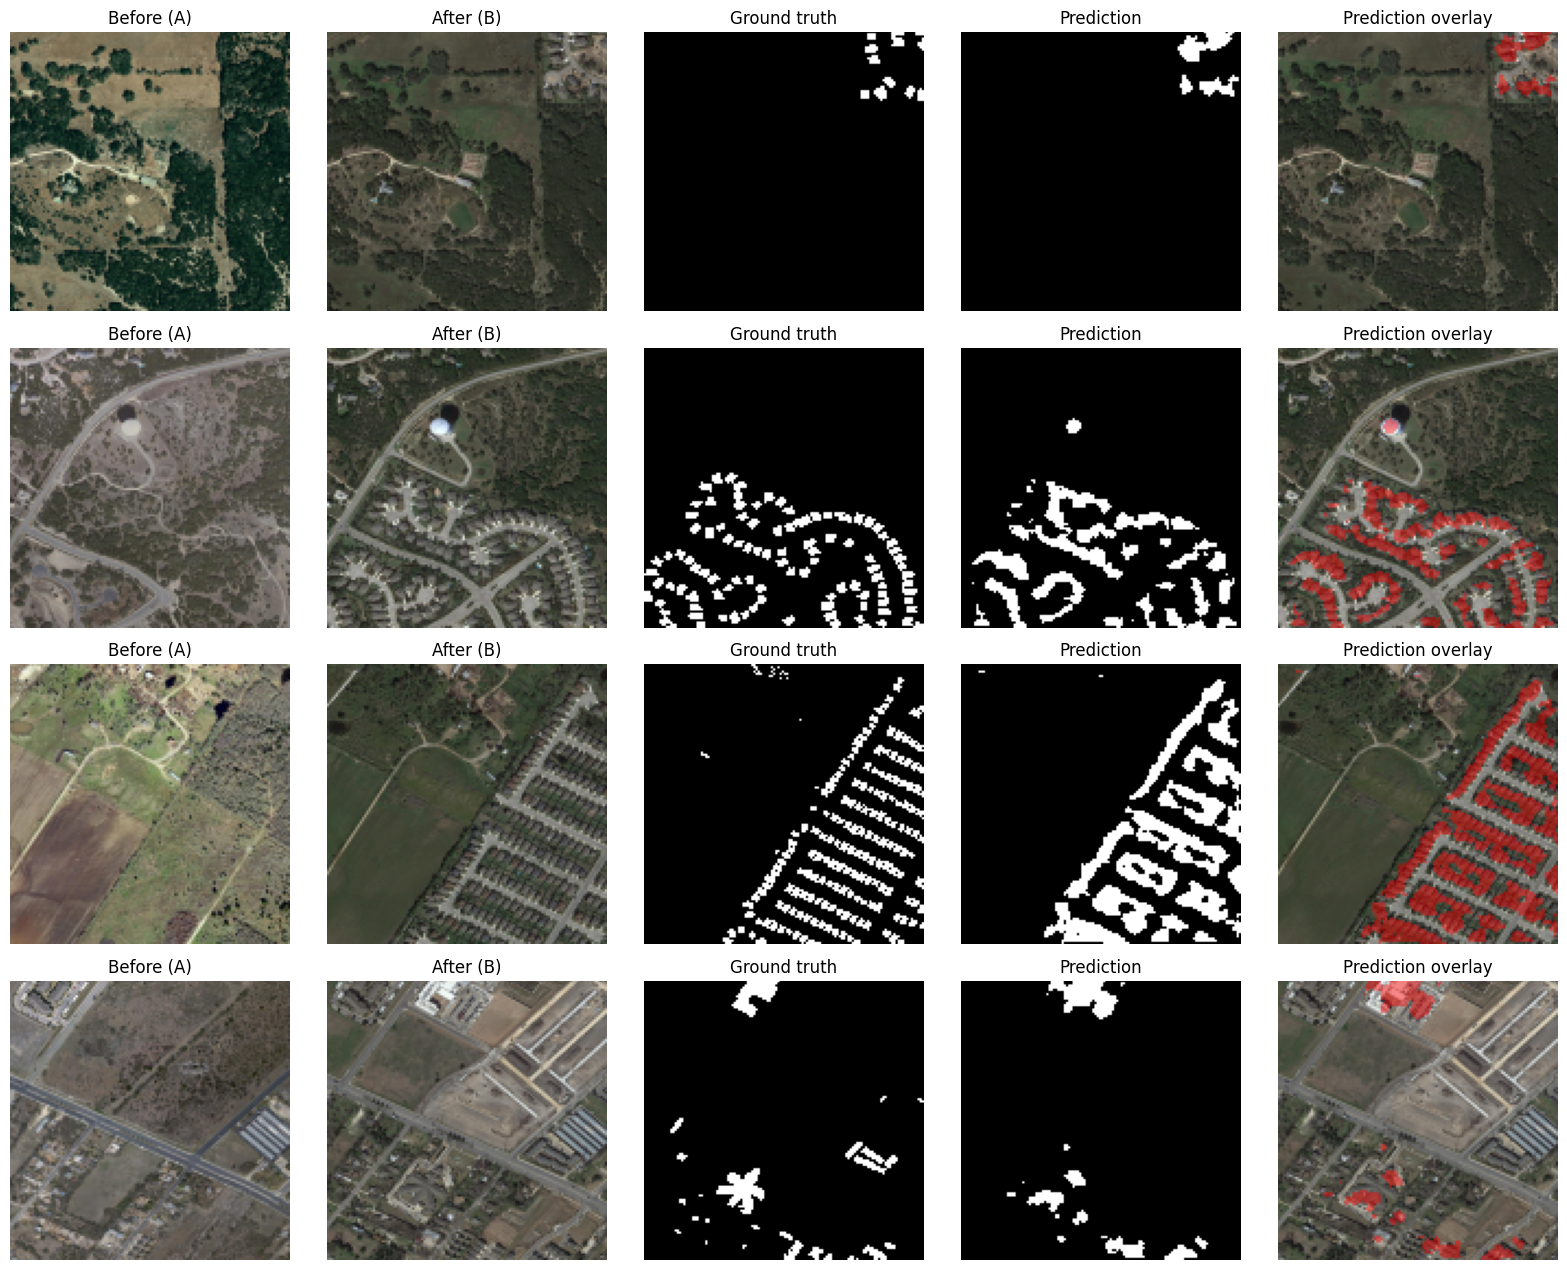

In [17]:
def visualize_predictions(Xa, Xb, Y, probabilities, threshold, indices=None, n=4):
    if indices is None:
        indices = list(range(min(n, len(Xa))))
    fig, axes = plt.subplots(len(indices), 5, figsize=(16, 3.2*len(indices)))
    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(indices):
        pred = (probabilities[idx, ..., 0] >= threshold).astype(np.uint8)
        gt = Y[idx, ..., 0]

        overlay = Xb[idx].copy()
        changed = pred == 1
        # Highlight predicted changes in red.
        overlay[changed] = (
            0.55 * overlay[changed] + 0.45 * np.array([255, 0, 0])
        ).astype(np.uint8)

        panels = [
            (Xa[idx], "Before (A)", None),
            (Xb[idx], "After (B)", None),
            (gt, "Ground truth", "gray"),
            (pred, "Prediction", "gray"),
            (overlay, "Prediction overlay", None)
        ]
        for col, (image, title, cmap) in enumerate(panels):
            axes[row, col].imshow(image, cmap=cmap, vmin=0, vmax=1 if cmap else None)
            axes[row, col].set_title(title)
            axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions(
    X1_test, X2_test, y_test, test_probs,
    BEST_THRESHOLD, indices=[0, 1, 2, 3]
)

## 16. Save the model and evaluation results

The final cell saves the trained model and the evaluation files to the experiment-specific Google Drive directory.

In [18]:
import shutil

DRIVE_OUTPUT = "/content/drive/MyDrive/LEVIR-CD_M1_outputs"
os.makedirs(DRIVE_OUTPUT, exist_ok=True)

shutil.copy2(FINAL_MODEL_PATH, os.path.join(DRIVE_OUTPUT, "M1_Siamese_UNet.keras"))
pd.DataFrame([test_results]).to_csv(
    os.path.join(DRIVE_OUTPUT, "M1_test_metrics.csv"), index=False
)
val_threshold_table.to_csv(
    os.path.join(DRIVE_OUTPUT, "M1_validation_thresholds.csv"), index=False
)

print("Saved M1 model and results to:", DRIVE_OUTPUT)

Saved M1 model and results to: /content/drive/MyDrive/LEVIR-CD_M1_outputs


## 17. Experiment summary

M1 is the reference model for the later experiments. It uses a shared ResNet50 encoder, absolute feature-difference fusion and a U-Net decoder. The held-out test metrics are reported in the evaluation output above.